In [ ]:
# ============================================================
# Synthetic-data conformal prediction experiments
#
# Datasets:
#   1. Three-mode switching AR system
#   2. Glucose simulator
#
# Methods:
#   - Standard CP
#   - ACI
#   - Proposed online mode-learning CP
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import deque
from dataclasses import dataclass

from sklearn.linear_model import Ridge
from scipy.stats import binom


# ------------------------------------------------------------
# Experimental settings
# ------------------------------------------------------------

ALPHA = 0.10

AR_ORDER = 24
RIDGE_LAMBDA = 1.0

# ACI learning rate
ACI_GAMMA = 0.005

# Proposed method
W = 168
N_BUILD = 168
DELTA = 0.01

# Rolling coverage
ROLLING_WINDOW = 168

# Initial data split
TRAIN_FRAC = 0.05
CAL_FRAC = 0.05

assert W == N_BUILD


# ------------------------------------------------------------
# IEEE-style plotting
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6,
    "axes.linewidth": 0.6,
    "lines.linewidth": 0.9,
    "figure.dpi": 300,
    "savefig.dpi": 600,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

In [ ]:
# ============================================================
# Load synthetic datasets
# ============================================================

three_mode_df = pd.read_csv(
    "three_mode_switching_dataset.csv"
)

glucose_df = pd.read_csv(
    "glucose_simulation_hourly.csv"
)


# ------------------------------------------------------------
# Check required columns
# ------------------------------------------------------------

required_three = {
    "time",
    "observation",
    "mode",
}

required_glucose = {
    "time_day",
    "glucose_observed_mg_dL",
    "true_mode_id",
    "true_mode_name",
}

if not required_three.issubset(three_mode_df.columns):
    raise ValueError(
        "Three-mode dataset is missing required columns."
    )

if not required_glucose.issubset(glucose_df.columns):
    raise ValueError(
        "Glucose dataset is missing required columns."
    )


# ------------------------------------------------------------
# Extract arrays
# ------------------------------------------------------------

three_x = three_mode_df[
    "time"
].to_numpy()

three_y = three_mode_df[
    "observation"
].to_numpy(dtype=float)

three_true_mode = three_mode_df[
    "mode"
].to_numpy(dtype=int)


glucose_x = glucose_df[
    "time_day"
].to_numpy(dtype=float)

glucose_y = glucose_df[
    "glucose_observed_mg_dL"
].to_numpy(dtype=float)

glucose_true_mode = glucose_df[
    "true_mode_id"
].to_numpy(dtype=int)


glucose_mode_names = {
    1: "Healthy",
    2: "Moderate untreated",
    3: "Severe untreated",
    4: "Beta-cell treatment",
}


print(
    "Three-mode observations:",
    len(three_y),
)

print(
    "Three-mode physical modes:",
    np.unique(three_true_mode),
)

print(
    "Glucose observations:",
    len(glucose_y),
)

print(
    "Glucose physical modes:",
    np.unique(glucose_true_mode),
)

Three-mode observations: 7000
Three-mode physical modes: [1 2 3]
Glucose observations: 8761
Glucose physical modes: [1 2 3 4]


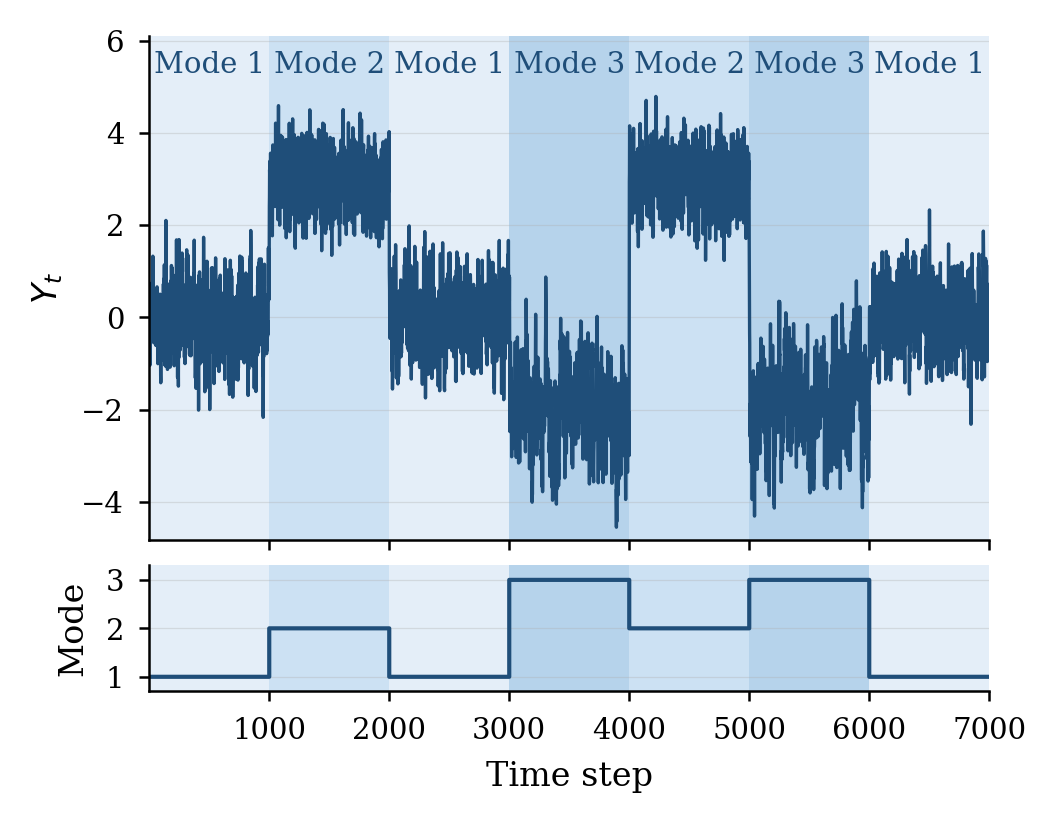

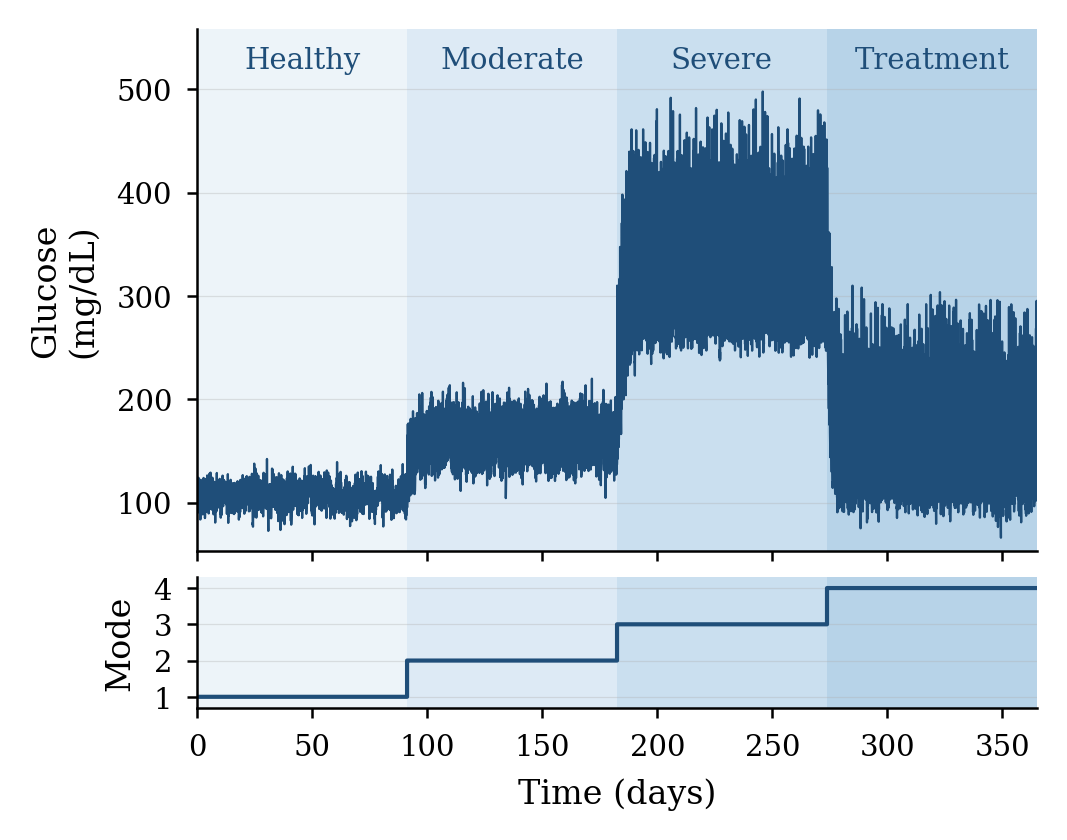

In [ ]:
# ============================================================
# Plot both synthetic datasets with true physical modes
# ============================================================

# ------------------------------------------------------------
# Common IEEE style
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6,
    "axes.linewidth": 0.6,
    "lines.linewidth": 0.9,
    "figure.dpi": 300,
    "savefig.dpi": 600,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

MAIN_BLUE = "#1f4e79"


def plot_mode_switching_series(
    x,
    y,
    mode,
    mode_names,
    mode_shading,
    ylabel,
    xlabel,
    save_name,
    figsize=(3.5, 2.8),
    line_width=0.8,
):
    """
    Plot a time series together with its ground-truth physical modes.

    Upper panel:
        observed time series with shaded mode regions.

    Lower panel:
        true physical-mode sequence.
    """

    x = np.asarray(x)
    y = np.asarray(y)
    mode = np.asarray(mode)

    # --------------------------------------------------------
    # Identify consecutive mode segments
    # --------------------------------------------------------

    changes = np.where(
        np.diff(mode) != 0
    )[0] + 1

    starts = np.r_[0, changes]
    ends = np.r_[changes, len(mode)]

    dt = np.median(
        np.diff(x)
    )

    # --------------------------------------------------------
    # Figure
    # --------------------------------------------------------

    fig, (ax_y, ax_mode) = plt.subplots(
        2,
        1,
        figsize=figsize,
        sharex=True,
        gridspec_kw={
            "height_ratios": [3.2, 0.8],
        },
    )

    # --------------------------------------------------------
    # Mode regions + labels
    # --------------------------------------------------------

    y_min = np.nanmin(y)
    y_max = np.nanmax(y)
    y_range = y_max - y_min

    label_y = (
        y_max
        + 0.04 * y_range
    )

    for start, end in zip(
        starts,
        ends,
    ):
        mode_id = int(
            mode[start]
        )

        start_x = x[start]
        end_x = x[end - 1] + dt

        for ax in (
            ax_y,
            ax_mode,
        ):
            ax.axvspan(
                start_x,
                end_x,
                color=mode_shading[mode_id],
                alpha=0.75,
                linewidth=0,
                zorder=0,
            )

        center_x = 0.5 * (
            x[start]
            + x[end - 1]
        )

        ax_y.text(
            center_x,
            label_y,
            mode_names.get(
                mode_id,
                f"Mode {mode_id}",
            ),
            ha="center",
            va="bottom",
            fontsize=7,
            color=MAIN_BLUE,
        )

    # --------------------------------------------------------
    # Upper panel: time series
    # --------------------------------------------------------

    ax_y.plot(
        x,
        y,
        color=MAIN_BLUE,
        linewidth=line_width,
        zorder=2,
    )

    ax_y.set_ylabel(
        ylabel
    )

    ax_y.set_ylim(
        y_min - 0.03 * y_range,
        y_max + 0.14 * y_range,
    )

    ax_y.grid(
        axis="y",
        linewidth=0.3,
        alpha=0.35,
    )

    # --------------------------------------------------------
    # Lower panel: true mode
    # --------------------------------------------------------

    unique_modes = sorted(
        np.unique(mode)
    )

    ax_mode.step(
        x,
        mode,
        where="post",
        color=MAIN_BLUE,
        linewidth=1.0,
        zorder=2,
    )

    ax_mode.set_xlabel(
        xlabel
    )

    ax_mode.set_ylabel(
        "Mode"
    )

    ax_mode.set_yticks(
        unique_modes
    )

    ax_mode.set_ylim(
        min(unique_modes) - 0.3,
        max(unique_modes) + 0.3,
    )

    ax_mode.grid(
        axis="y",
        linewidth=0.3,
        alpha=0.35,
    )

    # --------------------------------------------------------
    # Formatting
    # --------------------------------------------------------

    for ax in (
        ax_y,
        ax_mode,
    ):
        ax.margins(x=0)

        ax.spines[
            "top"
        ].set_visible(False)

        ax.spines[
            "right"
        ].set_visible(False)

        ax.tick_params(
            direction="out",
            length=2.5,
            width=0.6,
        )

    fig.subplots_adjust(
        left=0.18,
        right=0.98,
        top=0.94,
        bottom=0.16,
        hspace=0.08,
    )

    # --------------------------------------------------------
    # Save
    # --------------------------------------------------------

    fig.savefig(
        f"{save_name}.pdf",
        format="pdf",
        bbox_inches="tight",
    )

    fig.savefig(
        f"{save_name}.png",
        dpi=600,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)


# ============================================================
# Three-mode AR dataset
# ============================================================

plot_mode_switching_series(
    x=three_x,
    y=three_y,
    mode=three_true_mode,

    mode_names={
        1: "Mode 1",
        2: "Mode 2",
        3: "Mode 3",
    },

    mode_shading={
        1: "#dbe9f6",
        2: "#bcd7f0",
        3: "#9ec5e5",
    },

    ylabel=r"$Y_t$",
    xlabel="Time step",
    save_name="three_mode_switching_dataset",
    figsize=(3.5, 2.8),
    line_width=0.8,
)


# ============================================================
# Glucose dataset
# ============================================================

plot_mode_switching_series(
    x=glucose_x,
    y=glucose_y,
    mode=glucose_true_mode,

    mode_names={
        1: "Healthy",
        2: "Moderate",
        3: "Severe",
        4: "Treatment",
    },

    mode_shading={
        1: "#e8f1f8",
        2: "#d2e4f2",
        3: "#b9d5ea",
        4: "#9fc5e1",
    },

    ylabel="Glucose\n(mg/dL)",
    xlabel="Time (days)",
    save_name="glucose_mode_switching_dataset",
    figsize=(3.5, 2.9),
    line_width=0.55,
)

In [ ]:
# ============================================================
# AR(24) ridge predictor
# ============================================================

def fit_ar_ridge(
    y_train,
    lag=AR_ORDER,
    ridge_lambda=RIDGE_LAMBDA,
):

    y_train = np.asarray(
        y_train,
        dtype=float,
    )

    if len(y_train) <= lag:
        raise ValueError(
            "Training series must contain more observations "
            "than the AR order."
        )

    mean_y = np.mean(y_train)
    std_y = np.std(y_train)

    if std_y < 1e-12:
        std_y = 1.0

    X = []
    target = []

    for t in range(
        lag,
        len(y_train),
    ):

        x_t = np.array(
            [
                y_train[t - j]
                for j in range(
                    1,
                    lag + 1,
                )
            ],
            dtype=float,
        )

        x_t = (
            x_t - mean_y
        ) / std_y

        X.append(x_t)
        target.append(
            y_train[t]
        )

    X = np.asarray(X)
    target = np.asarray(target)

    model = Ridge(
        alpha=ridge_lambda,
        fit_intercept=True,
    )

    model.fit(
        X,
        target,
    )

    return {
        "model": model,
        "mean": mean_y,
        "std": std_y,
        "lag": lag,
    }


def predict_ar(
    ar_model,
    history,
    t,
):

    lag = ar_model[
        "lag"
    ]

    x_t = np.array(
        [
            history[t - j]
            for j in range(
                1,
                lag + 1,
            )
        ],
        dtype=float,
    )

    x_t = (
        x_t
        - ar_model["mean"]
    ) / ar_model["std"]

    prediction = (
        ar_model[
            "model"
        ]
        .predict(
            x_t.reshape(1, -1)
        )[0]
    )

    return float(
        prediction
    )

In [ ]:
# ============================================================
# Conformal utilities
# ============================================================

def conformal_quantile(
    scores,
    alpha,
):

    scores = np.asarray(
        scores,
        dtype=float,
    )

    n = len(scores)

    if n == 0:
        raise ValueError(
            "Calibration scores cannot be empty."
        )

    alpha = float(
        np.clip(
            alpha,
            0.0,
            1.0,
        )
    )

    k = int(
        np.ceil(
            (n + 1)
            * (1.0 - alpha)
        )
    )

    k = min(
        max(k, 1),
        n,
    )

    return float(
        np.partition(
            scores,
            k - 1,
        )[k - 1]
    )


def get_calibration_scores(
    ar_model,
    y,
    start,
    end,
):

    scores = []

    for t in range(
        start,
        end,
    ):

        pred = predict_ar(
            ar_model,
            y,
            t,
        )

        scores.append(
            abs(
                y[t] - pred
            )
        )

    return np.asarray(
        scores
    )


def compute_detection_threshold(
    W,
    alpha,
    delta,
):

    for j in range(
        W + 1
    ):

        tail_prob = binom.sf(
            j - 1,
            W,
            alpha,
        )

        if tail_prob <= delta:
            return j

    return W


DETECTION_THRESHOLD = (
    compute_detection_threshold(
        W,
        ALPHA,
        DELTA,
    )
)

print(
    "Detection threshold m =",
    DETECTION_THRESHOLD,
)

Detection threshold m = 27


In [ ]:
# ============================================================
# Standard conformal prediction
# ============================================================

def run_standard_cp(
    y,
    n_train,
    n_cal,
    alpha=ALPHA,
):

    y = np.asarray(
        y,
        dtype=float,
    )

    cal_start = n_train
    test_start = (
        n_train + n_cal
    )

    ar_model = fit_ar_ridge(
        y[:n_train]
    )

    cal_scores = (
        get_calibration_scores(
            ar_model,
            y,
            cal_start,
            test_start,
        )
    )

    q = conformal_quantile(
        cal_scores,
        alpha,
    )

    predictions = []
    lower = []
    upper = []
    covered = []
    widths = []

    for t in range(
        test_start,
        len(y),
    ):

        pred = predict_ar(
            ar_model,
            y,
            t,
        )

        lo = pred - q
        hi = pred + q

        predictions.append(
            pred
        )

        lower.append(
            lo
        )

        upper.append(
            hi
        )

        covered.append(
            lo <= y[t] <= hi
        )

        widths.append(
            hi - lo
        )

    return {
        "prediction":
            np.asarray(predictions),

        "lower":
            np.asarray(lower),

        "upper":
            np.asarray(upper),

        "covered":
            np.asarray(
                covered,
                dtype=bool,
            ),

        "width":
            np.asarray(widths),

        "q":
            q,

        "model":
            ar_model,

        "test_start":
            test_start,
    }

In [ ]:
# ============================================================
# Adaptive Conformal Inference
# ============================================================

def run_aci(
    y,
    n_train,
    n_cal,
    alpha=ALPHA,
    gamma=ACI_GAMMA,
):

    y = np.asarray(
        y,
        dtype=float,
    )

    cal_start = n_train
    test_start = (
        n_train + n_cal
    )

    ar_model = fit_ar_ridge(
        y[:n_train]
    )

    initial_scores = (
        get_calibration_scores(
            ar_model,
            y,
            cal_start,
            test_start,
        )
    )

    score_buffer = deque(
        initial_scores.tolist(),
        maxlen=n_cal,
    )

    alpha_t = alpha

    predictions = []
    lower = []
    upper = []
    covered = []
    widths = []

    for t in range(
        test_start,
        len(y),
    ):

        scores_now = np.asarray(
            score_buffer,
            dtype=float,
        )

        min_alpha = (
            1.0
            / (
                len(scores_now)
                + 1
            )
        )

        alpha_for_quantile = (
            np.clip(
                alpha_t,
                min_alpha,
                1.0,
            )
        )

        q_t = conformal_quantile(
            scores_now,
            alpha_for_quantile,
        )

        pred = predict_ar(
            ar_model,
            y,
            t,
        )

        lo = pred - q_t
        hi = pred + q_t

        miss = int(
            not (
                lo
                <= y[t]
                <= hi
            )
        )

        predictions.append(
            pred
        )

        lower.append(
            lo
        )

        upper.append(
            hi
        )

        covered.append(
            miss == 0
        )

        widths.append(
            hi - lo
        )

        # ACI update
        alpha_t = (
            alpha_t
            + gamma
            * (
                alpha
                - miss
            )
        )

        # Online score update
        new_score = abs(
            y[t] - pred
        )

        score_buffer.append(
            new_score
        )

    return {
        "prediction":
            np.asarray(predictions),

        "lower":
            np.asarray(lower),

        "upper":
            np.asarray(upper),

        "covered":
            np.asarray(
                covered,
                dtype=bool,
            ),

        "width":
            np.asarray(widths),

        "model":
            ar_model,

        "test_start":
            test_start,
    }

In [ ]:
# ============================================================
# Proposed method
# ============================================================

@dataclass
class ModeModel:
    mode_id: int
    ar_model: dict
    q: float
    created_at: int
    calibration_scores: np.ndarray


def build_mode_from_buffer(
    buffer,
    mode_id,
    created_at,
    alpha=ALPHA,
):

    buffer = np.asarray(
        buffer,
        dtype=float,
    )

    split = (
        len(buffer) // 2
    )

    if split <= AR_ORDER:
        raise ValueError(
            "Mode-building training portion "
            "is too short for AR(24)."
        )

    train_segment = (
        buffer[:split]
    )

    ar_model = fit_ar_ridge(
        train_segment
    )

    cal_scores = []

    for t in range(
        split,
        len(buffer),
    ):

        pred = predict_ar(
            ar_model,
            buffer,
            t,
        )

        cal_scores.append(
            abs(
                buffer[t]
                - pred
            )
        )

    q = conformal_quantile(
        cal_scores,
        alpha,
    )

    return ModeModel(
        mode_id=mode_id,
        ar_model=ar_model,
        q=q,
        created_at=created_at,
        calibration_scores=np.asarray(cal_scores),
    )


def interval_union_width(
    intervals,
):

    if len(intervals) == 0:
        return 0.0

    intervals = sorted(
        intervals,
        key=lambda x: x[0],
    )

    current_lo, current_hi = (
        intervals[0]
    )

    total_width = 0.0

    for lo, hi in intervals[1:]:

        if lo <= current_hi:

            current_hi = max(
                current_hi,
                hi,
            )

        else:

            total_width += (
                current_hi
                - current_lo
            )

            current_lo = lo
            current_hi = hi

    total_width += (
        current_hi
        - current_lo
    )

    return total_width


def run_mode_learning_cp(
    y,
    n_train,
    n_cal,
    alpha=ALPHA,
    W=W,
    n_build=N_BUILD,
    delta=DELTA,
):

    y = np.asarray(
        y,
        dtype=float,
    )

    test_start = (
        n_train + n_cal
    )

    threshold = (
        compute_detection_threshold(
            W,
            alpha,
            delta,
        )
    )

    # --------------------------------------------------------
    # Initial mode
    # --------------------------------------------------------

    initial_ar = fit_ar_ridge(
        y[:n_train]
    )

    initial_scores = (
        get_calibration_scores(
            initial_ar,
            y,
            n_train,
            test_start,
        )
    )

    initial_q = (
        conformal_quantile(
            initial_scores,
            alpha,
        )
    )

    modes = [
        ModeModel(
            mode_id=1,
            ar_model=initial_ar,
            q=initial_q,
            created_at=(
                test_start - 1
            ),
            calibration_scores=np.asarray(initial_scores),
        )
    ]

    # --------------------------------------------------------
    # Online state
    # --------------------------------------------------------

    error_window = deque(
        maxlen=W
    )

    collecting = False

    candidate_buffer = []

    detection_times = []
    mode_creation_times = []

    covered = []
    widths = []

    number_of_modes = []
    covering_modes_history = []

    # --------------------------------------------------------
    # Online prediction
    # --------------------------------------------------------

    for t in range(
        test_start,
        len(y),
    ):

        intervals = []
        covering_modes = []

        # Prediction interval from every learned mode
        for mode in modes:

            pred = predict_ar(
                mode.ar_model,
                y,
                t,
            )

            lo = pred - mode.q
            hi = pred + mode.q

            intervals.append(
                (lo, hi)
            )

            if lo <= y[t] <= hi:

                covering_modes.append(
                    mode.mode_id
                )

        is_covered = (
            len(
                covering_modes
            ) > 0
        )

        miss = int(
            not is_covered
        )

        covered.append(
            is_covered
        )

        widths.append(
            interval_union_width(
                intervals
            )
        )

        number_of_modes.append(
            len(modes)
        )

        covering_modes_history.append(
            covering_modes
        )

        # ----------------------------------------------------
        # Build a new mode after detection
        # ----------------------------------------------------

        if collecting:

            candidate_buffer.append(
                y[t]
            )

            if (
                len(candidate_buffer)
                >= n_build
            ):

                new_mode = (
                    build_mode_from_buffer(
                        candidate_buffer,
                        mode_id=(
                            len(modes) + 1
                        ),
                        created_at=t,
                        alpha=alpha,
                    )
                )

                modes.append(
                    new_mode
                )

                mode_creation_times.append(
                    t
                )

                collecting = False
                candidate_buffer = []

                error_window.clear()

        # ----------------------------------------------------
        # Detect persistent miscoverage
        # ----------------------------------------------------

        else:

            error_window.append(
                miss
            )

            if (
                len(error_window) == W
                and
                sum(error_window)
                >= threshold
            ):

                detection_times.append(
                    t
                )

                collecting = True
                candidate_buffer = []

                error_window.clear()

    return {
        "covered":
            np.asarray(
                covered,
                dtype=bool,
            ),

        "width":
            np.asarray(
                widths,
                dtype=float,
            ),

        "num_modes":
            np.asarray(
                number_of_modes,
                dtype=int,
            ),

        "covering_modes":
            covering_modes_history,

        "modes":
            modes,

        "detection_times":
            detection_times,

        "mode_creation_times":
            mode_creation_times,

        "threshold":
            threshold,

        "test_start":
            test_start,
    }

In [ ]:
# ============================================================
# Run experiments
# ============================================================

def run_synthetic_dataset(
    y,
):

    y = np.asarray(
        y,
        dtype=float,
    )

    N = len(y)

    n_train = int(
        np.floor(
            TRAIN_FRAC * N
        )
    )

    n_cal = int(
        np.floor(
            CAL_FRAC * N
        )
    )

    test_start = (
        n_train
        + n_cal
    )

    print(
        f"Total observations: {N}"
    )

    print(
        f"Training observations: {n_train}"
    )

    print(
        f"Calibration observations: {n_cal}"
    )

    print(
        f"Testing observations: {N - test_start}"
    )

    standard = run_standard_cp(
        y,
        n_train,
        n_cal,
    )

    aci = run_aci(
        y,
        n_train,
        n_cal,
    )

    proposed = run_mode_learning_cp(
        y,
        n_train,
        n_cal,
    )

    return {
        "n_train":
            n_train,

        "n_cal":
            n_cal,

        "test_start":
            test_start,

        "standard":
            standard,

        "aci":
            aci,

        "proposed":
            proposed,
    }


print(
    "\nTHREE-MODE AR"
)

three_results = (
    run_synthetic_dataset(
        three_y
    )
)


print(
    "\nGLUCOSE"
)

glucose_results = (
    run_synthetic_dataset(
        glucose_y
    )
)


THREE-MODE AR
Total observations: 7000
Training observations: 350
Calibration observations: 350
Testing observations: 6300

GLUCOSE
Total observations: 8761
Training observations: 438
Calibration observations: 438
Testing observations: 7885


In [ ]:
# ============================================================
# Overall results
# ============================================================

def overall_results_table(
    dataset_name,
    y,
    results,
):

    test_start = results[
        "test_start"
    ]

    y_test = y[
        test_start:
    ]

    rows = []

    for method, key in [
        ("Standard CP", "standard"),
        ("ACI", "aci"),
        ("Proposed", "proposed"),
    ]:

        result = results[
            key
        ]

        if "prediction" in result:

            rmse = np.sqrt(
                np.mean(
                    (
                        result[
                            "prediction"
                        ]
                        - y_test
                    ) ** 2
                )
            )

        else:

            rmse = np.nan

        rows.append({
            "Dataset":
                dataset_name,

            "Method":
                method,

            "Coverage":
                np.mean(
                    result["covered"]
                ),

            "Avg. Width":
                np.mean(
                    result["width"]
                ),

            "RMSE":
                rmse,

            "Modes Learned":
                (
                    len(
                        result["modes"]
                    )
                    if key == "proposed"
                    else np.nan
                ),

            "Detections":
                (
                    len(
                        result[
                            "detection_times"
                        ]
                    )
                    if key == "proposed"
                    else np.nan
                ),
        })

    return pd.DataFrame(
        rows
    )


three_overall = (
    overall_results_table(
        "Three-mode AR",
        three_y,
        three_results,
    )
)

glucose_overall = (
    overall_results_table(
        "Glucose",
        glucose_y,
        glucose_results,
    )
)


synthetic_overall_results = pd.concat(
    [
        three_overall,
        glucose_overall,
    ],
    ignore_index=True,
)


display(
    synthetic_overall_results
)

,Dataset,Method,Coverage,Avg. Width,RMSE,Modes Learned,Detections
0,Three-mode AR,Standard CP,0.483333,1.754889,1.216411,NaN,NaN
1,Three-mode AR,ACI,0.899683,3.379533,1.216411,NaN,NaN
2,Three-mode AR,Proposed,0.901270,6.104511,NaN,4.0,3.0
3,Glucose,Standard CP,0.484084,30.471191,41.263927,NaN,NaN
4,Glucose,ACI,0.899937,125.538092,41.263927,NaN,NaN
5,Glucose,Proposed,0.903361,92.522947,NaN,5.0,4.0


In [ ]:
# ============================================================
# Mode-specific coverage
# ============================================================

def mode_specific_results(
    dataset_name,
    true_mode,
    results,
    mode_names=None,
):

    true_mode = np.asarray(
        true_mode
    )

    test_start = results[
        "test_start"
    ]

    test_mode = true_mode[
        test_start:
    ]

    rows = []

    for mode_id in pd.unique(
        test_mode
    ):

        mask = (
            test_mode
            == mode_id
        )

        if mode_names is None:

            mode_label = (
                f"Mode {mode_id}"
            )

        else:

            mode_label = (
                mode_names.get(
                    mode_id,
                    f"Mode {mode_id}",
                )
            )

        for method, key in [
            ("Standard CP", "standard"),
            ("ACI", "aci"),
            ("Proposed", "proposed"),
        ]:

            result = results[
                key
            ]

            rows.append({
                "Dataset":
                    dataset_name,

                "Mode":
                    mode_label,

                "Method":
                    method,

                "Coverage":
                    np.mean(
                        result[
                            "covered"
                        ][mask]
                    ),

                "Avg. Width":
                    np.mean(
                        result[
                            "width"
                        ][mask]
                    ),

                "Samples":
                    int(
                        np.sum(mask)
                    ),
            })

    return pd.DataFrame(
        rows
    )


three_mode_results = (
    mode_specific_results(
        "Three-mode AR",
        three_true_mode,
        three_results,
    )
)


glucose_mode_results = (
    mode_specific_results(
        "Glucose",
        glucose_true_mode,
        glucose_results,
        glucose_mode_names,
    )
)


synthetic_mode_results = pd.concat(
    [
        three_mode_results,
        glucose_mode_results,
    ],
    ignore_index=True,
)


display(
    synthetic_mode_results
)

,Dataset,Mode,Method,Coverage,Avg. Width,Samples
0,Three-mode AR,Mode 1,Standard CP,0.900870,1.754889,2300
1,Three-mode AR,Mode 1,ACI,0.898696,1.985812,2300
2,Three-mode AR,Mode 1,Proposed,0.916957,6.137173,2300
3,Three-mode AR,Mode 2,Standard CP,0.088000,1.754889,2000
4,Three-mode AR,Mode 2,ACI,0.901500,4.797315,2000
5,Three-mode AR,Mode 2,Proposed,0.885000,5.225099,2000
6,Three-mode AR,Mode 3,Standard CP,0.398500,1.754889,2000
7,Three-mode AR,Mode 3,ACI,0.899000,3.564529,2000
8,Three-mode AR,Mode 3,Proposed,0.899500,6.946361,2000
9,Glucose,Healthy,Standard CP,0.932268,30.471191,1314


In [ ]:
# ============================================================
# True physical-mode segments
# ============================================================

def get_true_mode_segments(
    true_mode,
):

    true_mode = np.asarray(
        true_mode
    )

    changes = (
        np.where(
            true_mode[1:]
            != true_mode[:-1]
        )[0]
        + 1
    )

    starts = np.r_[
        0,
        changes,
    ]

    ends = np.r_[
        changes,
        len(true_mode),
    ]

    return [
        (
            int(start),
            int(end),
            int(
                true_mode[start]
            ),
        )
        for start, end
        in zip(
            starts,
            ends,
        )
    ]

In [ ]:
# ============================================================
# True transition / recurrence analysis
# ============================================================

def transition_analysis(
    dataset_name,
    x,
    true_mode,
    results,
    mode_names=None,
):

    x = np.asarray(x)
    true_mode = np.asarray(
        true_mode
    )

    test_start = results[
        "test_start"
    ]

    detections = results[
        "proposed"
    ][
        "detection_times"
    ]

    segments = (
        get_true_mode_segments(
            true_mode
        )
    )

    # Physical modes already present before testing
    seen_modes = set(
        true_mode[
            :test_start
        ]
    )

    rows = []

    for start, end, mode_id in segments:

        if start < test_start:
            seen_modes.add(
                mode_id
            )
            continue

        recurring = (
            mode_id
            in seen_modes
        )

        detections_here = [
            int(d)
            for d in detections
            if start <= d < end
        ]

        if len(
            detections_here
        ) > 0:

            first_detection = (
                detections_here[0]
            )

            delay = (
                first_detection
                - start
            )

            detection_x = (
                x[
                    first_detection
                ]
            )

        else:

            first_detection = np.nan
            delay = np.nan
            detection_x = np.nan

        if mode_names is None:

            mode_label = (
                f"Mode {mode_id}"
            )

        else:

            mode_label = (
                mode_names.get(
                    mode_id,
                    f"Mode {mode_id}",
                )
            )

        rows.append({
            "Dataset":
                dataset_name,

            "Mode Entered":
                mode_label,

            "Type":
                (
                    "Recurring"
                    if recurring
                    else "New"
                ),

            "True Start":
                x[start],

            "First Detection":
                detection_x,

            "Delay (samples)":
                delay,

            "Detections in Segment":
                len(
                    detections_here
                ),
        })

        seen_modes.add(
            mode_id
        )

    return pd.DataFrame(
        rows
    )


three_transition_results = (
    transition_analysis(
        "Three-mode AR",
        three_x,
        three_true_mode,
        three_results,
    )
)


glucose_transition_results = (
    transition_analysis(
        "Glucose",
        glucose_x,
        glucose_true_mode,
        glucose_results,
        glucose_mode_names,
    )
)


synthetic_transition_results = pd.concat(
    [
        three_transition_results,
        glucose_transition_results,
    ],
    ignore_index=True,
)


display(
    synthetic_transition_results
)

,Dataset,Mode Entered,Type,True Start,First Detection,Delay (samples),Detections in Segment
0,Three-mode AR,Mode 2,New,1001.00,1017.000000,16.0,1
1,Three-mode AR,Mode 1,Recurring,2001.00,NaN,NaN,0
2,Three-mode AR,Mode 3,New,3001.00,3028.000000,27.0,1
3,Three-mode AR,Mode 2,Recurring,4001.00,4011.000000,10.0,1
4,Three-mode AR,Mode 3,Recurring,5001.00,NaN,NaN,0
5,Three-mode AR,Mode 1,Recurring,6001.00,NaN,NaN,0
6,Glucose,Moderate untreated,New,91.25,93.833333,62.0,1
7,Glucose,Severe untreated,New,182.50,183.791667,31.0,2
8,Glucose,Beta-cell treatment,New,273.75,278.375000,111.0,1


In [ ]:
# ============================================================
# Every detector firing
# ============================================================

def detection_event_table(
    dataset_name,
    x,
    true_mode,
    results,
    mode_names=None,
):

    x = np.asarray(x)
    true_mode = np.asarray(
        true_mode
    )

    test_start = results[
        "test_start"
    ]

    proposed = results[
        "proposed"
    ]

    segments = (
        get_true_mode_segments(
            true_mode
        )
    )

    # Determine whether each physical segment
    # is new or recurring.
    seen = set(
        true_mode[
            :test_start
        ]
    )

    segment_info = []

    for start, end, mode_id in segments:

        if end <= test_start:

            seen.add(
                mode_id
            )

            continue

        recurring = (
            mode_id in seen
        )

        segment_info.append(
            (
                start,
                end,
                mode_id,
                recurring,
            )
        )

        seen.add(
            mode_id
        )

    rows = []

    for event_i, detection_idx in enumerate(
        proposed[
            "detection_times"
        ]
    ):

        detection_idx = int(
            detection_idx
        )

        match = None

        for (
            start,
            end,
            mode_id,
            recurring,
        ) in segment_info:

            if (
                start
                <= detection_idx
                < end
            ):

                match = (
                    start,
                    end,
                    mode_id,
                    recurring,
                )

                break

        if match is None:
            continue

        (
            start,
            end,
            mode_id,
            recurring,
        ) = match

        if mode_names is None:

            mode_label = (
                f"Mode {mode_id}"
            )

        else:

            mode_label = (
                mode_names.get(
                    mode_id,
                    f"Mode {mode_id}",
                )
            )

        if (
            event_i
            < len(
                proposed[
                    "mode_creation_times"
                ]
            )
        ):

            creation_idx = int(
                proposed[
                    "mode_creation_times"
                ][event_i]
            )

            creation_time = (
                x[
                    creation_idx
                ]
            )

        else:

            creation_time = np.nan

        rows.append({
            "Dataset":
                dataset_name,

            "Physical Mode":
                mode_label,

            "Physical Mode Type":
                (
                    "Recurring"
                    if recurring
                    else "New"
                ),

            "True Segment Start":
                x[start],

            "Detection Time":
                x[
                    detection_idx
                ],

            "Detection Delay (samples)":
                (
                    detection_idx
                    - start
                ),

            "Mode Learned Time":
                creation_time,
        })

    return pd.DataFrame(
        rows
    )


three_detection_results = (
    detection_event_table(
        "Three-mode AR",
        three_x,
        three_true_mode,
        three_results,
    )
)


glucose_detection_results = (
    detection_event_table(
        "Glucose",
        glucose_x,
        glucose_true_mode,
        glucose_results,
        glucose_mode_names,
    )
)


synthetic_detection_results = pd.concat(
    [
        three_detection_results,
        glucose_detection_results,
    ],
    ignore_index=True,
)


display(
    synthetic_detection_results
)

,Dataset,Physical Mode,Physical Mode Type,True Segment Start,Detection Time,Detection Delay (samples),Mode Learned Time
0,Three-mode AR,Mode 2,New,1001.00,1017.000000,16,1185.000000
1,Three-mode AR,Mode 3,New,3001.00,3028.000000,27,3196.000000
2,Three-mode AR,Mode 2,Recurring,4001.00,4011.000000,10,4179.000000
3,Glucose,Moderate untreated,New,91.25,93.833333,62,100.833333
4,Glucose,Severe untreated,New,182.50,183.791667,31,190.791667
5,Glucose,Severe untreated,New,182.50,200.333333,428,207.333333
6,Glucose,Beta-cell treatment,New,273.75,278.375000,111,285.375000


In [ ]:
# ============================================================
# Post-adaptation coverage
# ============================================================

def post_adaptation_results(
    dataset_name,
    x,
    true_mode,
    results,
    mode_names=None,
):

    x = np.asarray(x)
    true_mode = np.asarray(
        true_mode
    )

    test_start = results[
        "test_start"
    ]

    proposed = results[
        "proposed"
    ]

    segments = (
        get_true_mode_segments(
            true_mode
        )
    )

    rows = []

    for (
        start,
        end,
        mode_id,
    ) in segments:

        if end <= test_start:
            continue

        start = max(
            start,
            test_start,
        )

        creations = [
            int(c)
            for c in proposed[
                "mode_creation_times"
            ]
            if start <= c < end
        ]

        # If new conformal modes are constructed
        # inside this segment, evaluate after the
        # final construction.
        if len(creations) > 0:

            eval_start = (
                creations[-1]
                + 1
            )

        else:

            eval_start = start

        if eval_start >= end:
            continue

        local_start = (
            eval_start
            - test_start
        )

        local_end = (
            end
            - test_start
        )

        if mode_names is None:

            mode_label = (
                f"Mode {mode_id}"
            )

        else:

            mode_label = (
                mode_names.get(
                    mode_id,
                    f"Mode {mode_id}",
                )
            )

        rows.append({
            "Dataset":
                dataset_name,

            "Physical Mode":
                mode_label,

            "Evaluation Start":
                x[
                    eval_start
                ],

            "Samples":
                (
                    local_end
                    - local_start
                ),

            "Proposed Coverage":
                np.mean(
                    proposed[
                        "covered"
                    ][
                        local_start:
                        local_end
                    ]
                ),

            "Proposed Avg. Width":
                np.mean(
                    proposed[
                        "width"
                    ][
                        local_start:
                        local_end
                    ]
                ),
        })

    return pd.DataFrame(
        rows
    )


three_post = (
    post_adaptation_results(
        "Three-mode AR",
        three_x,
        three_true_mode,
        three_results,
    )
)


glucose_post = (
    post_adaptation_results(
        "Glucose",
        glucose_x,
        glucose_true_mode,
        glucose_results,
        glucose_mode_names,
    )
)


synthetic_post_results = pd.concat(
    [
        three_post,
        glucose_post,
    ],
    ignore_index=True,
)


display(
    synthetic_post_results
)

,Dataset,Physical Mode,Evaluation Start,Samples,Proposed Coverage,Proposed Avg. Width
0,Three-mode AR,Mode 1,701.000000,300,0.913333,1.754889
1,Three-mode AR,Mode 2,1186.000000,815,0.952147,4.307121
2,Three-mode AR,Mode 1,2001.000000,1000,0.896000,4.759964
3,Three-mode AR,Mode 3,3197.000000,804,0.932836,6.037316
4,Three-mode AR,Mode 2,4180.000000,821,0.996346,6.646895
5,Three-mode AR,Mode 3,5001.000000,1000,0.958000,8.105486
6,Three-mode AR,Mode 1,6001.000000,1000,0.939000,8.829068
7,Glucose,Healthy,36.500000,1314,0.932268,30.471191
8,Glucose,Moderate untreated,100.875000,1959,0.944359,49.189000
9,Glucose,Severe untreated,207.375000,1593,0.946642,123.333043


In [ ]:
# ============================================================
# Rolling coverage figures
# ============================================================

def plot_synthetic_rolling_coverage(
    x,
    true_mode,
    results,
    xlabel,
    ylabel,
    save_name,
):

    x = np.asarray(x)

    true_mode = np.asarray(
        true_mode
    )

    test_start = results[
        "test_start"
    ]

    x_test = x[
        test_start:
    ]

    fig, ax = plt.subplots(
        figsize=(3.5, 2.3)
    )

    # --------------------------------------------------------
    # Rolling coverage
    # --------------------------------------------------------

    for label, key in [
        ("Standard CP", "standard"),
        ("ACI", "aci"),
        ("Proposed", "proposed"),
    ]:

        rolling = (
            pd.Series(
                results[
                    key
                ][
                    "covered"
                ].astype(float)
            )
            .rolling(
                ROLLING_WINDOW,
                min_periods=ROLLING_WINDOW,
            )
            .mean()
            .to_numpy()
        )

        ax.plot(
            x_test,
            rolling,
            linewidth=0.9,
            label=label,
        )

    # Nominal coverage
    ax.axhline(
        1.0 - ALPHA,
        linestyle="--",
        linewidth=0.8,
        label="Target",
    )

    # --------------------------------------------------------
    # Known physical-mode transitions
    # --------------------------------------------------------

    change_idx = (
        np.where(
            true_mode[1:]
            != true_mode[:-1]
        )[0]
        + 1
    )

    change_idx = change_idx[
        change_idx
        >= test_start
    ]

    for i, idx in enumerate(change_idx):

      ax.axvline(
          x[idx],
          linestyle=":",
          linewidth=0.7,
          color="0.35",
          label=(
              "True mode change"
              if i == 0
              else None
          ),
      )
    '''
    # --------------------------------------------------------
    # Detected shifts
    # --------------------------------------------------------

    for i, idx in enumerate(
        results[
            "proposed"
        ][
            "detection_times"
        ]
    ):

        ax.axvline(
            x[
                int(idx)
            ],
            linestyle="--",
            linewidth=0.8,
            color="red",
            label=(
                "Shift detected"
                if i == 0
                else None
            ),
        )
    '''

    # --------------------------------------------------------
    # New mode learned
    # --------------------------------------------------------

    for i, idx in enumerate(
        results[
            "proposed"
        ][
            "mode_creation_times"
        ]
    ):

        ax.axvline(
            x[
                int(idx)
            ],
            linestyle="--",
            linewidth=0.8,
            color="red",
            label=(
                "New mode learned"
                if i == 0
                else None
            ),
        )

    # --------------------------------------------------------
    # Formatting
    # --------------------------------------------------------

    ax.set_xlabel(
        xlabel
    )

    ax.set_ylabel(
        ylabel
    )

    ax.set_ylim(
        0.0,
        1.02,
    )

    ax.grid(
        axis="y",
        linewidth=0.3,
        alpha=0.35,
    )

    ax.margins(
        x=0
    )

    ax.spines[
        "top"
    ].set_visible(
        False
    )

    ax.spines[
        "right"
    ].set_visible(
        False
    )

    ax.tick_params(
        direction="out",
        length=2.5,
        width=0.6,
    )

    # Same one-column lower-right legend
    ax.legend(
        frameon=False,
        ncol=1,
        loc="lower right",
        bbox_to_anchor=(
            1.2,
            0.02,
        ),
        borderaxespad=0.0,
    )

    fig.subplots_adjust(
        left=0.18,
        right=0.98,
        top=0.96,
        bottom=0.21,
    )

    plt.savefig(
        f"{save_name}.pdf",
        format="pdf",
        bbox_inches="tight",
    )

    plt.savefig(
        f"{save_name}.png",
        dpi=600,
        bbox_inches="tight",
    )

    plt.show()

    plt.close(
        fig
    )

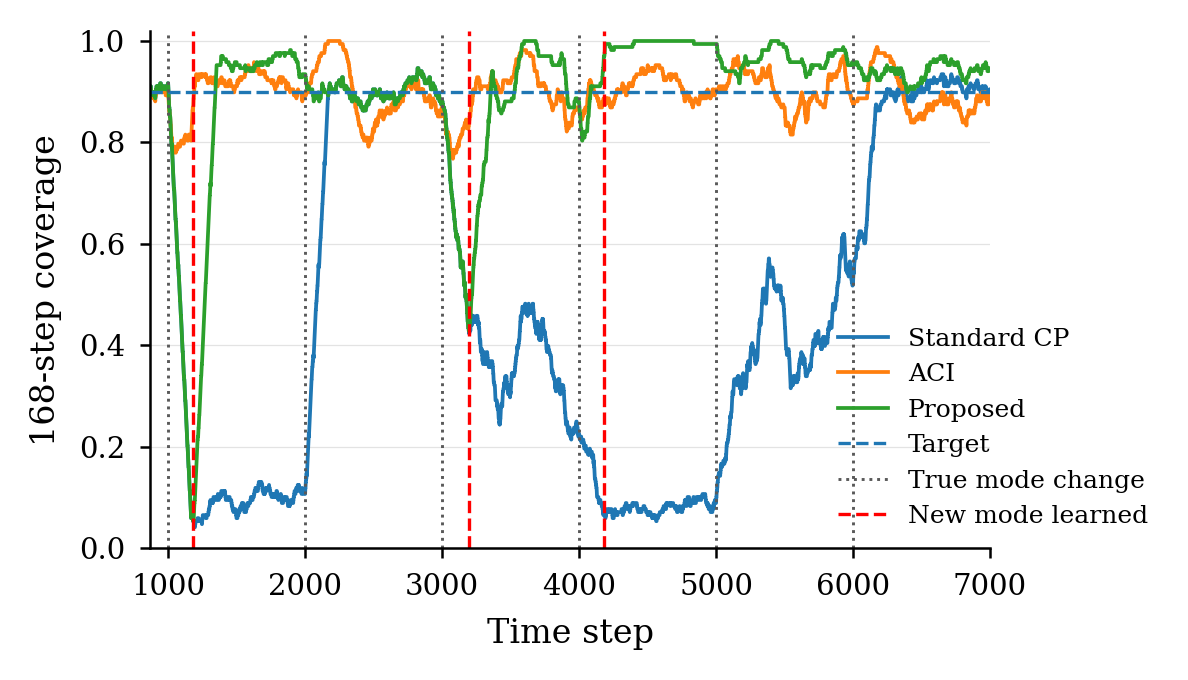

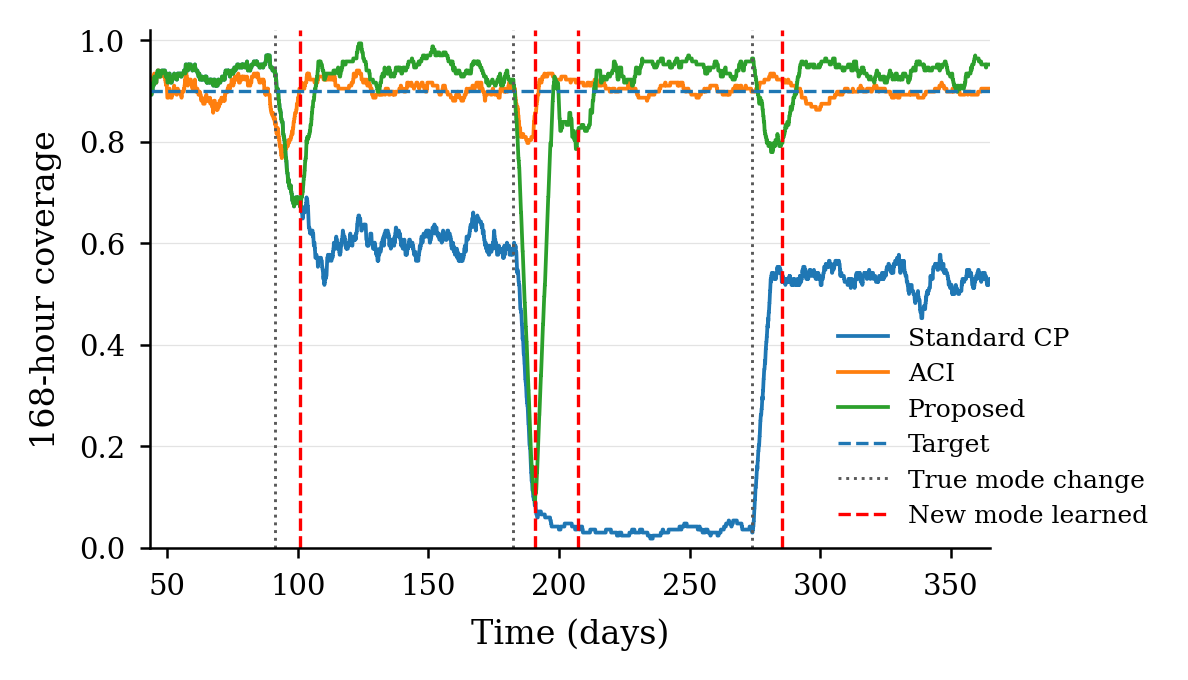

In [ ]:
# ------------------------------------------------------------
# Three-mode AR
# ------------------------------------------------------------

plot_synthetic_rolling_coverage(
    x=three_x,
    true_mode=three_true_mode,
    results=three_results,
    xlabel="Time step",
    ylabel="168-step coverage",
    save_name=(
        "three_mode_rolling_coverage"
    ),
)


# ------------------------------------------------------------
# Glucose
# ------------------------------------------------------------

plot_synthetic_rolling_coverage(
    x=glucose_x,
    true_mode=glucose_true_mode,
    results=glucose_results,
    xlabel="Time (days)",
    ylabel="168-hour coverage",
    save_name=(
        "glucose_rolling_coverage"
    ),
)

In [ ]:
# ============================================================
# Detector details
# ============================================================

print(
    "Detection threshold:",
    DETECTION_THRESHOLD,
)


print("\nThree-mode AR")

print(
    "Learned conformal modes:",
    len(
        three_results[
            "proposed"
        ]["modes"]
    ),
)

print(
    "Detected shifts:",
    three_results[
        "proposed"
    ]["detection_times"],
)

print(
    "Mode learned times:",
    three_results[
        "proposed"
    ]["mode_creation_times"],
)


print("\nGlucose")

print(
    "Learned conformal modes:",
    len(
        glucose_results[
            "proposed"
        ]["modes"]
    ),
)

print(
    "Detected shifts:",
    glucose_results[
        "proposed"
    ]["detection_times"],
)

print(
    "Mode learned times:",
    glucose_results[
        "proposed"
    ]["mode_creation_times"],
)

Detection threshold: 27

Three-mode AR
Learned conformal modes: 4
Detected shifts: [1016, 3027, 4010]
Mode learned times: [1184, 3195, 4178]

Glucose
Learned conformal modes: 5
Detected shifts: [2252, 4411, 4808, 6681]
Mode learned times: [2420, 4579, 4976, 6849]


In [ ]:
# ============================================================
# Save results
# ============================================================

synthetic_overall_results.to_csv(
    "synthetic_overall_results.csv",
    index=False,
)

synthetic_mode_results.to_csv(
    "synthetic_mode_specific_results.csv",
    index=False,
)

synthetic_transition_results.to_csv(
    "synthetic_transition_results.csv",
    index=False,
)

synthetic_detection_results.to_csv(
    "synthetic_detection_results.csv",
    index=False,
)

synthetic_post_results.to_csv(
    "synthetic_post_adaptation_results.csv",
    index=False,
)

In [ ]:
# Synthetic rows of Table III. All forecasts and detection times were computed above.
from scipy.stats import ks_2samp


def synthetic_alarm_tests(dataset, values, results):
    omac = results["proposed"]
    records = []
    for number, alarm in enumerate(omac["detection_times"], start=1):
        active_modes = [mode for mode in omac["modes"] if mode.created_at < alarm]
        raw_p = []
        for mode in active_modes:
            alarm_scores = get_calibration_scores(
                mode.ar_model, values, alarm - W + 1, alarm + 1
            )
            raw_p.append(ks_2samp(mode.calibration_scores, alarm_scores).pvalue)

        # Holm correction across the modes active at this single alarm.
        order = np.argsort(raw_p)
        ranked = np.asarray(raw_p)[order] * np.arange(len(order), 0, -1)
        adjusted = np.empty(len(order))
        adjusted[order] = np.minimum(1, np.maximum.accumulate(ranked))
        for mode, raw, adj in zip(active_modes, raw_p, adjusted):
            records.append({
                "Dataset": dataset, "Detection": number, "Existing Mode": mode.mode_id,
                "Alarm index": int(alarm), "Raw p-value": raw, "Holm p-value": adj
            })
    return records


synthetic_detection_window_tests = pd.DataFrame(
    synthetic_alarm_tests("Three-mode AR", three_y, three_results)
    + synthetic_alarm_tests("Glucose", glucose_y, glucose_results)
)
display(synthetic_detection_window_tests)
synthetic_detection_window_tests.to_csv("synthetic_detection_window_tests.csv", index=False)


Dataset,Detection,Existing Mode,Alarm index,Raw p-value,Holm p-value
Three-mode AR,1,1,1016,4.055842e-01,4.055842e-01
Three-mode AR,2,1,3027,1.487772e-01,1.487772e-01
Three-mode AR,2,2,3027,8.188412e-69,1.637682e-68
Three-mode AR,3,1,4010,2.338574e-55,4.677149e-55
Three-mode AR,3,2,4010,8.188412e-69,2.456524e-68
Three-mode AR,3,3,4010,3.269416e-02,3.269416e-02
Glucose,1,1,2252,2.153828e-02,2.153828e-02
Glucose,2,1,4411,1.222892e-14,2.445784e-14
Glucose,2,2,4411,1.921934e-02,1.921934e-02
Glucose,3,1,4808,2.708610e-118,8.125831e-118
